In [116]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [117]:
import os, sys, re, random, time
import importlib, traceback

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
import tqdm

import torch
from torch import nn
from torch.nn import functional as F
from torch.utils import data

import data_loaders
import miscellaneous
from rs_algorithm.models import RegressionBasedBPEModel, ThreeTowerRecommender
from rs_algorithm.models import AdaptiveRepresentation, SequenceRepresentation
from rs_algorithm.models.user_models.user_02_sim import DynamicPreferenceUserModel
from dl_trainer import Trainer, split_collate

In [118]:
data_model = data_loaders.KuaiRecData(root='../data/KuaiRec2.0', initial_specimen='smaller')

In [119]:
try:
    ds_train = data_model.get_dataset()
    smaller_matrix = miscellaneous.keyed_cache("kuairec_smaller_matrix", lambda: data_model.subsample_specimen('small', 10000))
    ds_test = data_model.get_bpr_dataset(smaller_matrix)
except:
    traceback.print_exc()

In [120]:
try:
    d_embed = 1024
    n_users, d_user_feats = data_model.user_features.shape
    n_items, d_item_feats = data_model.item_features.shape
    n_users, d_user_feats = data_model.ratings['user_id'].nunique(), data_model.user_features.shape[1]
    n_items, d_item_feats = data_model.ratings['item_id'].nunique(), data_model.item_features.shape[1]

    uid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['user_id']))}
    user_model = AdaptiveRepresentation(n_users, d_user_feats, d_hidden=1024, d_embed=d_embed, id2idx=uid2idx)
    iid2idx = {v: i for i, v in enumerate(np.unique(data_model.ratings['item_id']))}
    item_model = AdaptiveRepresentation(n_items, d_item_feats, d_hidden=1024, d_embed=d_embed, id2idx=iid2idx)
    model = RegressionBasedBPEModel(user_model, item_model)
except:
    traceback.print_exc()

In [121]:
try:
    trainer = Trainer(model=model, train_dataloader=data.DataLoader(ds_train, batch_size=8192))
except:
    traceback.print_exc()

In [122]:
try:
    # trainer.load_checkpoint('checkpoint_RegressionBasedBPEModel_001_20260402_171557_0.7496953347667319.pt', save_backup=False)
    trainer.load_checkpoint('model_embedder_v4.1_mse_only.pt', save_backup=False)
except:
    traceback.print_exc()

In [123]:
try:
    history_model = SequenceRepresentation('gru', d_embed, d_embed)
    for mod in (user_model, item_model):
        for par in mod.parameters():
            par.requires_grad = False
    recommender = ThreeTowerRecommender(d_embed, user_model, item_model, history_model)
except:
    traceback.print_exc()

In [130]:
try:
    with torch.no_grad():
        (uid, uft, pid, pif, nid, nif), truth = next(iter(ds_test))
        uid, uft, pid, pif, nid, nif = (
            torch.tensor([uid], dtype=torch.int64), torch.tensor(uft[None, :], dtype=torch.float32),
            torch.tensor([pid], dtype=torch.int64), torch.tensor(pif[None, :], dtype=torch.float32),
            torch.tensor([nid], dtype=torch.int64), torch.tensor(nif[None, :], dtype=torch.float32))

        hid = torch.cat([nid, nid, nid], dim=0)
        hft = torch.cat([nif, nif, nif], dim=0)
        msk = torch.ones((1, 3))
        emb, *_ = recommender(uid, uft, hid, hft, msk)

        uem, ubs = user_model(uid, uft)
        pie, pib = item_model(pid, pif)
        nie, nib = item_model(nid, nif)

        print((uem * pie).mean(dim=1) + ubs + pib)
        print((uem * nie).mean(dim=1) + ubs + nib)
        print((uem * emb).mean(dim=1) + ubs)
except:
    traceback.print_exc()

tensor([-0.3444])
tensor([-0.0457])
tensor([0.1332])


In [194]:
class UserModelDataset(data.Dataset):
    def __init__(self, data_model: 'DataModel', history_zise, length=1024, ratings=None):
        self.data_model = data_model
        self.ratings: pd.DataFrame = ratings if ratings is not None else data_model.ratings
        self.ratings = self.ratings.sample(frac=1)
        self.history_size = history_zise
        self.length = length
        self.users = {}
        for uid in self.ratings['user_id'].unique():
            with torch.no_grad():
                uem, ubs = user_model(
                    torch.tensor([uid], dtype=torch.int64),
                    torch.tensor(self.data_model.get_user_features(uid)[None, :], dtype=torch.float32))
                uem, ubs = uem.numpy(), ubs.numpy().squeeze()
            self.users[uid] = DynamicPreferenceUserModel(uem, preference_function=lambda preference, item, bias: (preference * item).sum() + ubs + bias.squeeze())
        self.flip = True

    def __len__(self):
        # Actual length of ratings matrix is 998100
        # But data is infinite because of user model
        # So we can just iterate indefinitely
        # return len(self.ratings)
        return self.length

    def __getitem__(self, idx: int):
        idx = random.randint(0, len(self.ratings) - 1)
        user_id = self.ratings.iloc[idx]['user_id'].astype(np.int64)
        user_feats = self.data_model.get_user_features(user_id)
        user = self.users[user_id]
        user.reset()

        hist_id = []
        hist_feats = []
        hist_clk = []

        for iid in self.ratings.sample(random.randint(5, self.history_size))['item_id']:
            ift = self.data_model.get_item_features(iid)
            hist_id.append(iid), hist_feats.append(ift)
            with torch.no_grad():
                iem, ibs = item_model(
                    torch.tensor([iid], dtype=torch.int64),
                    torch.tensor(ift[None, :], dtype=torch.float32))
                clk = np.int64(user.react(None, None, iem.numpy(), ibs.numpy()))
                hist_clk.append(clk)
                # print(iem.std(), user.preference.std())

        subset = data_model.ratings[data_model.ratings['user_id'] == user_id]
        if self.flip:
            # print("flip T", end=' ')
            subset = subset[subset['rating'] > 0.75]
        else:
            # print("flip F", end=' ')
            subset = subset[subset['rating'] <= 0.75]
        for iid in subset.sample(1)['item_id']:
            ift = self.data_model.get_item_features(iid)
            with torch.no_grad():
                iem, ibs = item_model(
                    torch.tensor([iid], dtype=torch.int64),
                    torch.tensor(ift[None, :], dtype=torch.float32))
                clk = np.int64(user.react(None, None, iem.numpy(), ibs.numpy()))
                # print(clk)

        self.flip = not self.flip

        return ((
                    user_id,
                    user_feats,
                    np.array(hist_id, dtype=np.int64),
                    np.array(hist_feats, dtype=np.float32),
                    np.array(hist_clk, dtype=np.int64),
                ), (
                    iem.flatten(),
                    clk,
                ))


try:
    umd = UserModelDataset(data_model, 20, length=128)
except:
    traceback.print_exc()

In [195]:
try:
    pos = []
    neg = []
    for _, ((uid, uft, hids, hfts, hclk), (iem, clk)) in zip(tqdm.tqdm(range(len(umd))), umd):
        if umd.flip: pos.append(clk)
        else: neg.append(clk)
    print(len(pos), len(neg))
    print(np.mean(pos), np.mean(neg))
except:
    traceback.print_exc()

  5%|▍         | 6/128 [00:00<00:04, 27.97it/s]

tensor(0.6254) 0.57011396
tensor(0.6234) 0.5690618
tensor(0.6190) 0.5680139
tensor(0.6340) 0.5669688
tensor(0.6501) 0.56592757
tensor(0.6119) 0.56489336
tensor(0.6585) 0.5638632
tensor(0.6344) 0.56283695
tensor(0.6230) 0.56181365
tensor(0.6197) 0.5607956
tensor(0.6339) 0.5597822
tensor(0.6257) 0.55877227
tensor(0.6173) 0.5577661
tensor(0.6294) 0.5567644
tensor(0.6261) 0.55576795
tensor(0.6217) 0.5547739
tensor(0.6649) 0.5537871
tensor(0.6584) 0.5528056
tensor(0.6307) 0.55182433
tensor(0.6337) 0.5508496
tensor(0.6816) 0.6306916
tensor(0.6260) 0.6306916
tensor(0.6643) 0.6295223
tensor(0.6206) 0.628358
tensor(0.6514) 0.6271976
tensor(0.6257) 0.6260422
tensor(0.6208) 0.62975883
tensor(0.6268) 0.62975883
tensor(0.6586) 0.62975883
tensor(0.6831) 0.62859124
tensor(0.6254) 0.62859124
tensor(0.6202) 0.6274275
tensor(0.6345) 0.6262686
tensor(0.6341) 0.5938452
tensor(0.6275) 0.5927481
tensor(0.6264) 0.5916548
tensor(0.6659) 0.59056747
tensor(0.6196) 0.589484
tensor(0.6191) 0.5884049
tensor(0.6740

  7%|▋         | 9/128 [00:00<00:04, 28.30it/s]

tensor(0.6256) 0.63676697
tensor(0.6551) 0.63559127
tensor(0.6600) 0.63441956
tensor(0.6229) 0.6332519
tensor(0.6238) 0.6320882
tensor(0.6581) 0.6309306
tensor(0.6252) 0.6297754
tensor(0.6275) 0.6286234
tensor(0.6216) 0.62747717
tensor(0.6304) 0.6263348
tensor(0.6586) 0.6251989
tensor(0.6176) 0.6240646
tensor(0.6495) 0.62293595
tensor(0.6169) 0.6218088
tensor(0.6196) 0.6205147
tensor(0.6205) 0.6193689
tensor(0.6340) 0.61822546
tensor(0.6614) 0.6170859
tensor(0.6598) 0.61595345
tensor(0.6198) 0.6148236
tensor(0.6260) 0.61369836
tensor(0.6231) 0.6252535
tensor(0.6259) 0.6252535
tensor(0.6342) 0.6240966
tensor(0.6182) 0.6229422
tensor(0.6602) 0.6217938
tensor(0.6599) 0.62064993
tensor(0.6847) 0.61951
tensor(0.6238) 0.6183743
tensor(0.6342) 0.6172436
tensor(0.6233) 0.61611617
tensor(0.6554) 0.6149948
tensor(0.6578) 0.6138774
tensor(0.6231) 0.6127622
tensor(0.6608) 0.61165226
tensor(0.6262) 0.61054814
tensor(0.6296) 0.6094472
tensor(0.6534) 0.60835254
tensor(0.6237) 0.61215824
tensor(0.6128

 15%|█▍        | 19/128 [00:00<00:04, 27.19it/s]

tensor(0.6244) 0.61546665
tensor(0.6587) 0.61432946
tensor(0.6206) 0.6131964
tensor(0.6209) 0.61206734
tensor(0.6258) 0.61094254
tensor(0.6482) 0.6098224
tensor(0.6278) 0.6087047
tensor(0.6845) 0.60759515
tensor(0.6343) 0.6064887
tensor(0.6278) 0.6053858
tensor(0.6257) 0.60428673
tensor(0.6257) 0.6031922
tensor(0.6628) 0.6021037
tensor(0.6584) 0.60101944
tensor(0.6338) 0.6308258
tensor(0.6249) 0.6296566
tensor(0.6206) 0.6284885
tensor(0.6195) 0.62732756
tensor(0.6326) 0.62617064
tensor(0.6559) 0.6250199
tensor(0.6200) 0.6238726
tensor(0.6272) 0.6227291
tensor(0.6307) 0.6215893
tensor(0.6578) 0.6204558
tensor(0.6614) 0.6193267
tensor(0.6187) 0.6181994
tensor(0.6338) 0.6170787
tensor(0.6194) 0.61595994
tensor(0.6339) 0.61484843
tensor(0.6143) 0.6137366
tensor(0.6270) 0.612633
tensor(0.6342) 0.6115318
tensor(0.6340) 0.6104355
tensor(0.6262) 0.6093434
tensor(0.6149) 0.61158806
tensor(0.6636) 0.61045676
tensor(0.6230) 0.60933006
tensor(0.6272) 0.6082082
tensor(0.6226) 0.6070907
tensor(0.616

... (38 outputs left out)

 98%|█████████▊| 126/128 [00:05<00:00, 22.87it/s]

tensor(0.6265) 0.6096213
tensor(0.6270) 0.608496
tensor(0.6303) 0.6073759
tensor(0.6588) 0.6062595
tensor(0.6163) 0.605147
tensor(0.6524) 0.6040409
tensor(0.6200) 0.56626326
tensor(0.6561) 0.56626326
tensor(0.6175) 0.56521153
tensor(0.6227) 0.5641665
tensor(0.6598) 0.56312555
tensor(0.6227) 0.56208783
tensor(0.6173) 0.5610559
tensor(0.6268) 0.5600278
tensor(0.6247) 0.55900437
tensor(0.6653) 0.5579862
tensor(0.6336) 0.55697244
tensor(0.6256) 0.555961
tensor(0.6340) 0.55495733
tensor(0.6148) 0.58852094
tensor(0.6614) 0.5874325
tensor(0.6632) 0.5863476
tensor(0.6234) 0.58526736
tensor(0.6207) 0.58419025
tensor(0.6073) 0.58311486
tensor(0.6134) 0.5820478
tensor(0.6580) 0.5809866
tensor(0.6581) 0.57992756
tensor(0.6307) 0.57887137
tensor(0.6149) 0.5778186
tensor(0.6271) 0.5767721
tensor(0.6320) 0.57572997
tensor(0.6339) 0.57469386
tensor(0.6267) 0.5736607
tensor(0.6587) 0.5726339
tensor(0.6344) 0.5716102
tensor(0.6183) 0.5705896
tensor(0.6274) 0.5695731
tensor(0.6206) 0.56856173
tensor(0.63

100%|██████████| 128/128 [00:05<00:00, 24.93it/s]

tensor(0.7115) 0.6503017
tensor(0.6326) 0.6503017
tensor(0.6199) 0.64909774
tensor(0.6268) 0.647896
tensor(0.6613) 0.646701
tensor(0.6554) 0.6455094
tensor(0.6199) 0.64432204
tensor(0.6246) 0.64313954
tensor(0.6632) 0.6419614
64 64
1.0 1.0


In [187]:
try:
    pos = 0
    neg = 0
    for _, ((uid, uft, hids, hfts, hclk), (iem, clk)) in zip(tqdm.tqdm(range(len(umd))), umd):
        if clk == 1: pos += 1
        else: neg += 1
    print(pos, neg)
except:
    traceback.print_exc()

  5%|▍         | 6/128 [00:00<00:04, 25.11it/s]

flip T 1
flip F 1
flip T 0
flip F 1
flip T 1
flip F 1


  7%|▋         | 9/128 [00:00<00:05, 23.40it/s]

flip T 1
flip F 1
flip T 1
flip F 0
flip T 1


 12%|█▏        | 15/128 [00:00<00:04, 22.97it/s]

flip F 1
flip T 1
flip F 1
flip T 1
flip F 1


... (34 outputs left out)

 98%|█████████▊| 125/128 [00:04<00:00, 32.02it/s]

flip F 1
flip T 1
flip F 1
flip T 1
flip F 1
flip T 1
flip F 1
flip T 0


100%|██████████| 128/128 [00:04<00:00, 26.14it/s]

flip F 1
110 18


In [166]:
try:
    # print(next(iter(umd)))
    print((np.random.rand(1, 122) * np.random.rand(1, 122)).sum())
    print(np.random.rand(1, 1).squeeze())
except:
    traceback.print_exc()

31.995006102507602
0.01101280551457584


In [164]:
len(umd)

128

In [110]:
try:
    for _, ((uid, uft, hids, hfts, hclk), (iem, clk)) in zip(range(1), umd):
        print(uid)
        print((umd.users[uid].preference * iem).sum())
        print(clk)
except:
    traceback.print_exc()

2414
5.7098875
0.0


In [39]:
def bce_loss(preds, truth):
    uem, (ubs, hbs) = preds
    iem, clk = truth
    if ubs is None: ubs = 0
    # print('uem', uem.shape, 'ubs', ubs.shape, 'iem', iem.shape, 'clk', clk.shape)
    rel = torch.sigmoid((uem * iem).sum(dim=1) + ubs)
    # print('rel', rel.shape)
    return F.binary_cross_entropy(rel, clk)


def mse_loss(preds, truth):
    uem, (ubs, hbs) = preds
    iem, clk = truth
    if ubs is None: ubs = 0
    rel = torch.sigmoid((uem * iem).sum(dim=1) + ubs)
    print(rel)
    return F.mse_loss(rel, clk)


def collate_fn(list_of_stuff):
    uid, uft, hid, hft, seq = tuple(zip(*([x[0] for x in list_of_stuff])))
    uid = torch.tensor(uid)
    uft = torch.tensor(uft)
    max_seq = max(seq)
    hid = torch.tensor([np.pad(x, (0, max_seq - len(x))) for x in hid])
    hft = torch.tensor([np.pad(x, [(0, max_seq - len(x)), (0, 0)]) for x in hft])
    mask = torch.tensor([[i < len(x) for i in range(max_seq)] for x in hid], dtype=torch.float32)
    iem, clk = tuple(zip(*([x[1] for x in list_of_stuff])))
    iem = torch.tensor(iem)
    clk = torch.tensor(clk)
    return (uid, uft, hid, hft, mask), (iem, clk)

In [12]:
loss = None

In [43]:
try:
    trainer = Trainer(
        model=recommender,
        train_dataloader=data.DataLoader(umd, batch_size=4096, collate_fn=collate_fn),
        epochs=1,
        dataset_fraction=1,
        # criterion=bce_loss,
        criterion=mse_loss,
        optimizer=lambda x: torch.optim.Adam(x, lr=0.01),
        record_per_epoch_training_loss=True,
        record_per_batch_training_loss=True,
        loss=loss,
    )
    loss = trainer.loss
except:
    traceback.print_exc()

In [44]:
try:
    trainer.train()
except:
    traceback.print_exc()

tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 

dict_keys(['train', 'val', 'epoch.train', 'batch.train'])
61


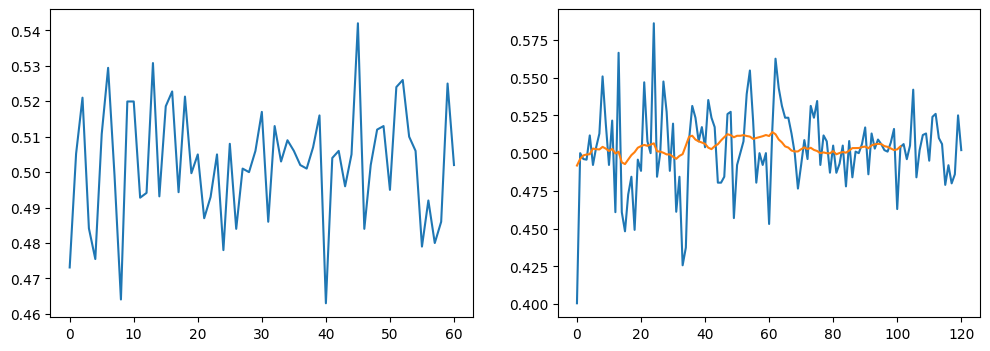

In [31]:
try:
    def running_average(arr, window=20):
        return np.convolve(arr, np.ones(window), 'valid') / window


    print(trainer.loss.keys())
    print(len(trainer.loss['epoch.train']))
    _, axs = plt.subplots(1, 2, figsize=(12, 4))
    axs[0].plot(trainer.loss['train'])
    axs[1].plot(trainer.loss['batch.train'])
    axs[1].plot(running_average(trainer.loss['batch.train']))
except:
    traceback.print_exc()

In [82]:
try:
    print(len(trainer.loss['batch.train']))
    # trainer.loss['batch.train'] = trainer.loss['batch.train'][250:]
except:
    traceback.print_exc()

366
